### A1 · ¿Son de mesoescala los temporales que pierde el XGB?
Para cada temporal observado (Hs > U99, picos separados 72 h, 1985–2025; tabla `temporales_xgb.csv` del 04) se mira la atmósfera en el pico (paso de 6 h más cercano), real (ERA5) y reconstruida con las 30 PCs, y se calculan indicadores de escala:
- **Lo que no ven las PCs:** error del campo reconstruido en una caja alrededor de Baleares y cociente gradiente reconstruido / gradiente real en esa caja.
- **Tamaño y posición de la baja:** presión mínima del dominio, distancia al sitio y curvatura (laplaciano) en el mínimo: una baja compacta tiene curvatura alta.
- **Dirección del flujo:** viento geostrófico en el sitio (de dónde viene).
- **Duración** del temporal observado por encima de U99.

Hipótesis: los perdidos son cortos, con bajas compactas y cercanas que las PCs reconstruyen mal, sobre todo en otoño y con flujos del SE/SW.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from bluemath_tk.core.io import load_model
from bluemath_tk.core.operations import spatial_gradient

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    CARTOPY = True
except Exception:
    CARTOPY = False
print("cartopy:", CARTOPY)

cartopy: True


#### Configuración

In [4]:
ZARR = "data/era5_mslp_grad_1985_2026_1deg_hourly.zarr"          # ← ruta del zarr en el clúster
point = "p102"
SITIO = dict(lat=39.604, lon=3.625)
CAJA = dict(latitude=slice(42, 37), longitude=slice(1, 7))       # Baleares y su entorno (≈ 6° × 5°)
CORTES = [0, 0.5, 0.8, np.inf]                                    # perdido < 0.5 ≤ parcial < 0.8 ≤ pillado
CLASES = ["perdido", "parcial", "pillado"]

TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
COLOR = {"perdido": NARANJA, "parcial": GRIS, "pillado": AZUL}
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.spines.top": False, "axes.spines.right": False,
})

In [5]:
from bluemath_tk.datamining import PCA
from sklearn.decomposition import PCA as PCA_

#### PCA de presión reajustada aquí (el pickle del 01 lleva datos enlazados al zarr local y no se abre en otra máquina)
era5_6h = xr.open_zarr(ZARR).rename({"valid_time": "time"})
era5_6h = era5_6h.sel(time=era5_6h.time.dt.hour.isin([0, 6, 12, 18]))
era5_6h = era5_6h.sel(latitude=slice(48, 30), longitude=slice(-5, 20))

pca_msl = PCA(n_components=30)
pca_msl._pca = PCA_(n_components=30, svd_solver="covariance_eigh")
pca_msl.fit_transform(data=era5_6h[["msl"]].sel(time=slice("1985-01-01", "2015-12-31")), vars_to_stack=["msl"],
                      coords_to_stack=["latitude", "longitude"], pca_dim_for_rows="time")

#### Comprobación: las PCs de esta PCA tienen que coincidir con las del CSV
t_chk = pcs.index[:200]
pcs_chk = pca_msl.transform(data=era5_6h[["msl"]].sel(time=t_chk))["PCs"].values
print("máx |dif| PCs:", np.abs(pcs_chk - pcs.loc[t_chk].values).max().round(4))

2026-11-27 09:07:31,063 - PCA - WARNING - Using PCA
2026-11-27 09:07:32,278 - PCA - WARNING - Using 450 out of 450 available variables 
If this is originated by using few times, please check 'nan_threshold_to_drop' parameter in fit method


NameError: name 'pcs' is not defined

#### Datos: temporales, PCs, PCA y ERA5 (dominio Mediterráneo occidental)

In [ ]:
temporales = pd.read_csv(f"outputs/xgb_{point}/temporales_xgb.csv", index_col=0, parse_dates=True)
temporales["clase"] = pd.cut(temporales["ratio"], CORTES, labels=CLASES, right=False)      # mismo corte siempre
temporales["t6"] = temporales.index.round("6h")
print(temporales["clase"].value_counts().reindex(CLASES))

pcs = pd.read_csv("outputs/pca/pcs_msl_30_6h.csv", index_col=0, parse_dates=True)
hs_obs = pd.read_csv(f"inputs/waves_bulk_{point}.csv", index_col=0, parse_dates=True)["VHM0"].loc["1985":"2025"]
U99 = hs_obs.quantile(0.99)

era5 = xr.open_zarr(ZARR).rename({"valid_time": "time"})
era5 = era5.sel(latitude=slice(48, 30), longitude=slice(-5, 20))

clase
perdido     21
parcial    130
pillado    104
Name: count, dtype: int64


#### Campos en el pico: real (ERA5) y reconstruido con las 30 PCs

In [6]:
t6 = pd.DatetimeIndex(temporales["t6"], name="time")
real = era5[["msl", "grad2"]].sel(time=t6).load()

pcs_da = xr.DataArray(pcs.loc[t6].values, dims=("time", "n_component"),
                      coords={"time": t6, "n_component": np.arange(pcs.shape[1])})
msl_rec = pca_msl.inverse_transform(pcs_da)["msl"].transpose("time", "latitude", "longitude")
grad_rec = spatial_gradient(msl_rec)
msl_real = real["msl"].transpose("time", "latitude", "longitude")
grad_real = real["grad2"].transpose("time", "latitude", "longitude")
print(msl_real.shape, msl_rec.shape)

NameError: name 'temporales' is not defined

#### Indicadores por temporal

In [7]:
R_T = 6371.0
lat2d, lon2d = np.meshgrid(msl_real.latitude.values, msl_real.longitude.values, indexing="ij")

def distancia_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * R_T * np.arcsin(np.sqrt(a))

def derivadas(campo):
    """dp/dx, dp/dy [hPa/100 km] y laplaciano [hPa/(100 km)²] de un campo (lat, lon) en Pa."""
    p = campo / 100.0
    lat = msl_real.latitude.values
    dy = np.gradient(lat) * 111.2 / 100                                   # en unidades de 100 km (signo según el orden)
    dx = np.gradient(msl_real.longitude.values)[None, :] * 111.2 * np.cos(np.radians(lat))[:, None] / 100
    dpdy = np.gradient(p, axis=0) / dy[:, None]
    dpdx = np.gradient(p, axis=1) / dx
    lap = np.gradient(dpdx, axis=1) / dx + np.gradient(dpdy, axis=0) / dy[:, None]
    return dpdx, dpdy, lap

i_s = int(np.abs(msl_real.latitude.values - SITIO["lat"]).argmin())
j_s = int(np.abs(msl_real.longitude.values - SITIO["lon"]).argmin())
SECTORES = np.array(["N", "NE", "E", "SE", "S", "SW", "W", "NW"])

filas = []
for k, t in enumerate(t6):
    pr, pc = msl_real.isel(time=k), msl_rec.isel(time=k)
    cr, cc = pr.sel(**CAJA), pc.sel(**CAJA)
    ar, ac = cr - cr.mean(), cc - cc.mean()
    gr, gc = grad_real.isel(time=k).sel(**CAJA).mean().item(), grad_rec.isel(time=k).sel(**CAJA).mean().item()

    v = pr.values
    i_m, j_m = np.unravel_index(np.argmin(v), v.shape)
    dpdx, dpdy, lap = derivadas(v)
    u_g, v_g = -dpdy[i_s, j_s], dpdx[i_s, j_s]                            # viento geostrófico (proporcional)
    dir_de = (np.degrees(np.arctan2(-u_g, -v_g)) + 360) % 360             # dirección de la que viene

    filas.append({"rmse caja [hPa]": float(np.sqrt(((cr - cc) ** 2).mean())) / 100,
                  "corr caja": float(np.corrcoef(ar.values.ravel(), ac.values.ravel())[0, 1]),
                  "grad rec / real": gc / gr,
                  "p mín [hPa]": v.min() / 100,
                  "dist baja [km]": distancia_km(SITIO["lat"], SITIO["lon"], lat2d[i_m, j_m], lon2d[i_m, j_m]),
                  "curvatura baja": lap[i_m, j_m],
                  "|∇p| sitio": np.hypot(dpdx[i_s, j_s], dpdy[i_s, j_s]),
                  "dir flujo [°]": dir_de,
                  "sector": SECTORES[int(((dir_de + 22.5) % 360) // 45)]})

ind = pd.DataFrame(filas, index=temporales.index)

#### Duración observada por encima de U99 del episodio que contiene el pico
serie = hs_obs.asfreq("h")
def duracion(t):
    sobre = (serie > U99).astype(int)
    ini, fin = t, t
    while sobre.get(ini - pd.Timedelta("1h"), 0) == 1: ini -= pd.Timedelta("1h")
    while sobre.get(fin + pd.Timedelta("1h"), 0) == 1: fin += pd.Timedelta("1h")
    return (fin - ini) / pd.Timedelta("1h") + 1
ind["duración > U99 [h]"] = [duracion(t) for t in temporales.index]

datos = temporales[["hs_obs", "ratio", "clase", "periodo", "estacion"]].join(ind)
datos.head()

NameError: name 'msl_real' is not defined

#### ¿En qué se diferencian perdidos, parciales y pillados?

In [ ]:
VARS = ["rmse caja [hPa]", "corr caja", "grad rec / real", "p mín [hPa]", "dist baja [km]",
        "curvatura baja", "|∇p| sitio", "duración > U99 [h]", "hs_obs"]

display(datos.groupby("clase", observed=True)[VARS].median().round(2).T)

#### Correlación de rangos con el cociente f/obs (en todos los temporales)
pd.Series({v: spearmanr(datos[v], datos["ratio"], nan_policy="omit")[0] for v in VARS}, name="Spearman con f/obs").round(2)

clase,perdido,parcial,pillado
rmse caja [hPa],0.640000,0.580000,0.520000
corr caja,0.970000,0.980000,0.990000
grad rec / real,0.720000,0.840000,0.900000
p mín [hPa],998.359985,1000.859985,1004.419983
dist baja [km],1027.390000,833.610000,834.770000
curvatura baja,2.680000,2.160000,2.070000
|∇p| sitio,2.210000,2.140000,1.990000
duración > U99 [h],5.000000,8.000000,11.000000
hs_obs,4.080000,4.330000,4.310000


rmse caja [hPa]      -0.16
corr caja             0.19
grad rec / real       0.16
p mín [hPa]           0.23
dist baja [km]       -0.03
curvatura baja       -0.06
|∇p| sitio           -0.06
duración > U99 [h]    0.20
hs_obs                0.04
Name: Spearman con f/obs, dtype: float64

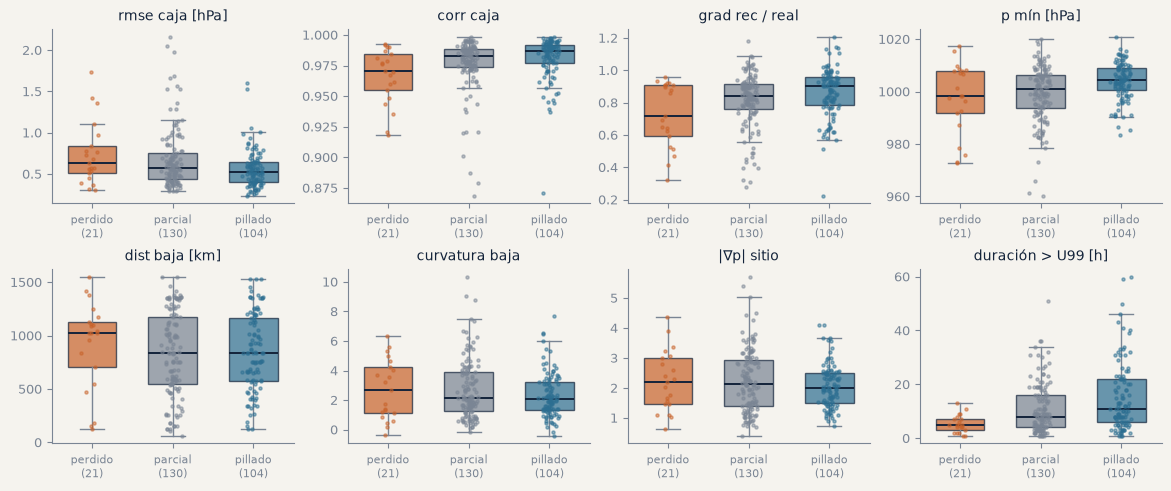

In [ ]:
fig, axs = plt.subplots(2, 4, figsize=(11.6, 4.8), constrained_layout=True)
for ax, v in zip(axs.flat, VARS[:8]):
    grupos = [datos.loc[datos.clase == c, v].dropna().values for c in CLASES]
    bp = ax.boxplot(grupos, widths=0.6, showfliers=False, patch_artist=True,
                    medianprops=dict(color=TINTA, lw=1.4), whiskerprops=dict(color=GRIS), capprops=dict(color=GRIS))
    for caja, c in zip(bp["boxes"], CLASES):
        caja.set_facecolor(COLOR[c]); caja.set_alpha(0.7); caja.set_edgecolor(TINTA)
    for x, (g, c) in enumerate(zip(grupos, CLASES), start=1):
        ax.scatter(np.random.default_rng(0).normal(x, 0.06, len(g)), g, s=5, color=COLOR[c], alpha=0.5, zorder=3)
    ax.set_xticks([1, 2, 3], [f"{c}\n({len(g)})" for c, g in zip(CLASES, grupos)], fontsize=8)
    ax.set_title(v, fontsize=10)
fig.savefig("figuras/temporales_clase_indicadores.png", dpi=200)
plt.show()

In [ ]:
#### Estación y sector del flujo por clase (fracción de cada clase)
display(pd.crosstab(datos["estacion"], datos["clase"], normalize="columns").round(2))
pd.crosstab(datos["sector"], datos["clase"], normalize="columns").reindex(SECTORES).round(2)

clase,perdido,parcial,pillado
estacion,,,
invierno,0.24,0.50,0.62
otoño,0.48,0.26,0.21
primavera,0.14,0.24,0.17
verano,0.14,0.00,0.00


clase,perdido,parcial,pillado
sector,,,
N,0.62,0.62,0.66
NE,0.10,0.17,0.24
E,0.00,0.04,0.06
SE,0.05,0.01,0.02
S,0.00,0.01,0.00
SW,0.05,0.05,0.01
W,0.14,0.03,0.00
NW,0.05,0.08,0.01


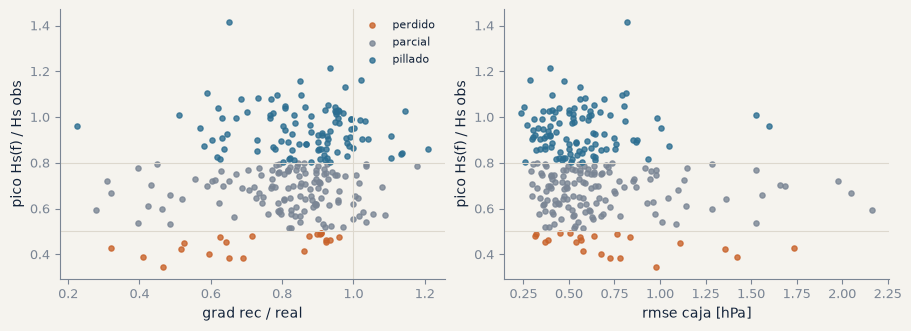

In [ ]:
#### Lo que no ven las PCs frente a lo que pierde el XGB
fig, axs = plt.subplots(1, 2, figsize=(9.0, 3.2), constrained_layout=True)
for ax, v in zip(axs, ["grad rec / real", "rmse caja [hPa]"]):
    for c in CLASES:
        d = datos[datos.clase == c]
        ax.scatter(d[v], d["ratio"], s=14, color=COLOR[c], alpha=0.8, label=c)
    ax.axhline(0.5, color="#DDD8CE", lw=0.8); ax.axhline(0.8, color="#DDD8CE", lw=0.8)
    ax.set(xlabel=v, ylabel="pico Hs(f) / Hs obs")
axs[0].axvline(1, color="#DDD8CE", lw=0.8)
axs[0].legend(frameon=False, fontsize=8)
fig.savefig("figuras/temporales_reconstruccion_vs_ratio.png", dpi=200)
plt.show()

clase,perdido,parcial,pillado
techo 6 h,0.94,0.96,0.97
ratio,0.45,0.69,0.93
duración > U99 [h],5.00,8.00,11.00


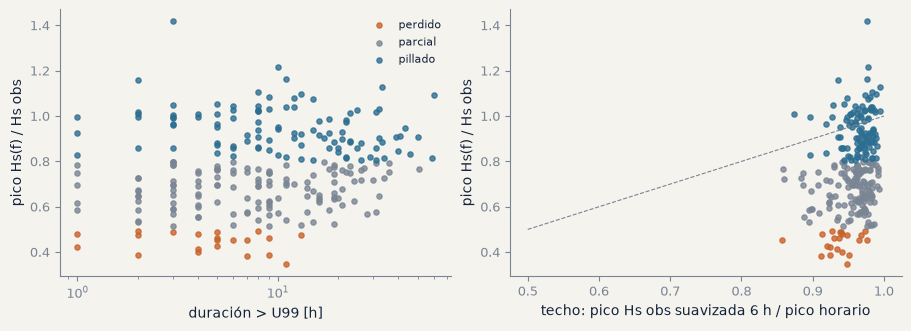

In [ ]:
#### Techo por resolución temporal: pico de la Hs observada suavizada 6 h (lo que ve el objetivo del XGB) / pico horario
hs_6h = hs_obs.asfreq("h").rolling("6h", center=True).mean()
datos["techo 6 h"] = [hs_6h.loc[t - pd.Timedelta("24h"):t + pd.Timedelta("24h")].max() / datos.loc[t, "hs_obs"] for t in datos.index]

display(datos.groupby("clase", observed=True)[["techo 6 h", "ratio", "duración > U99 [h]"]].median().round(2).T)

fig, axs = plt.subplots(1, 2, figsize=(9.0, 3.2), constrained_layout=True)
for c in CLASES:
    d = datos[datos.clase == c]
    axs[0].scatter(d["duración > U99 [h]"], d["ratio"], s=14, color=COLOR[c], alpha=0.8, label=c)
    axs[1].scatter(d["techo 6 h"], d["ratio"], s=14, color=COLOR[c], alpha=0.8)
axs[0].set(xscale="log", xlabel="duración > U99 [h]", ylabel="pico Hs(f) / Hs obs")
axs[1].plot([0.5, 1], [0.5, 1], color=GRIS, lw=0.8, ls="--")
axs[1].set(xlabel="techo: pico Hs obs suavizada 6 h / pico horario", ylabel="pico Hs(f) / Hs obs")
axs[0].legend(frameon=False, fontsize=8)
fig.savefig("figuras/temporales_resolucion_temporal.png", dpi=200)
plt.show()

#### Compuestos por clase: presión real, reconstruida y lo que se pierde

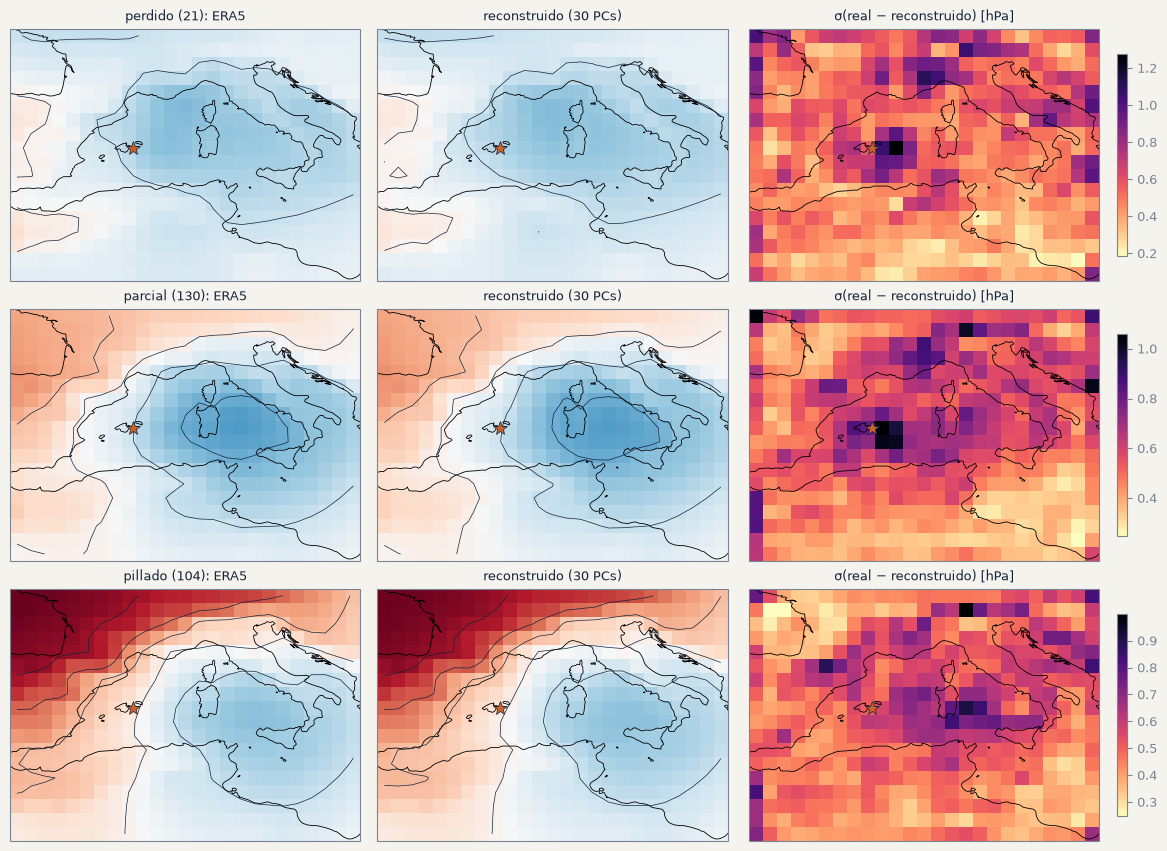

In [ ]:
def mapa(ax, campo, titulo, cmap="RdBu_r", vlim=None, contornos=None):
    kw = dict(transform=ccrs.PlateCarree()) if CARTOPY else {}
    lon, lat = campo.longitude.values, campo.latitude.values
    vmin, vmax = (-vlim, vlim) if vlim else (None, None)
    im = ax.pcolormesh(lon, lat, campo.values, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto", **kw)
    if contornos is not None:
        ax.contour(lon, lat, contornos.values, levels=np.arange(960, 1040, 4), colors=TINTA, linewidths=0.5, **kw)
    if CARTOPY:
        ax.coastlines(resolution="50m", lw=0.6)
    ax.plot(SITIO["lon"], SITIO["lat"], "*", color=NARANJA, ms=10, mec=TINTA, mew=0.5, **kw)
    ax.set_title(titulo, fontsize=9)
    return im

sub = dict(projection=ccrs.PlateCarree()) if CARTOPY else {}
fig, axs = plt.subplots(3, 3, figsize=(11.6, 8.4), constrained_layout=True, subplot_kw=sub)
for f, c in enumerate(CLASES):
    sel = (datos["clase"] == c).values
    pr = msl_real.isel(time=sel).mean("time") / 100
    pc = msl_rec.isel(time=sel).mean("time") / 100
    clim = float(msl_real.mean().item()) / 100
    mapa(axs[f, 0], pr - clim, f"{c} ({sel.sum()}): ERA5", vlim=15, contornos=pr)
    mapa(axs[f, 1], pc - clim, "reconstruido (30 PCs)", vlim=15, contornos=pc)
    im = mapa(axs[f, 2], (msl_real.isel(time=sel) - msl_rec.isel(time=sel)).std("time") / 100,
              "σ(real − reconstruido) [hPa]", cmap="magma_r")
    fig.colorbar(im, ax=axs[f, 2], shrink=0.8)
fig.savefig("figuras/temporales_compuestos_clase.png", dpi=200)
plt.show()

#### Los perdidos, uno a uno: campo real vs reconstruido en el pico

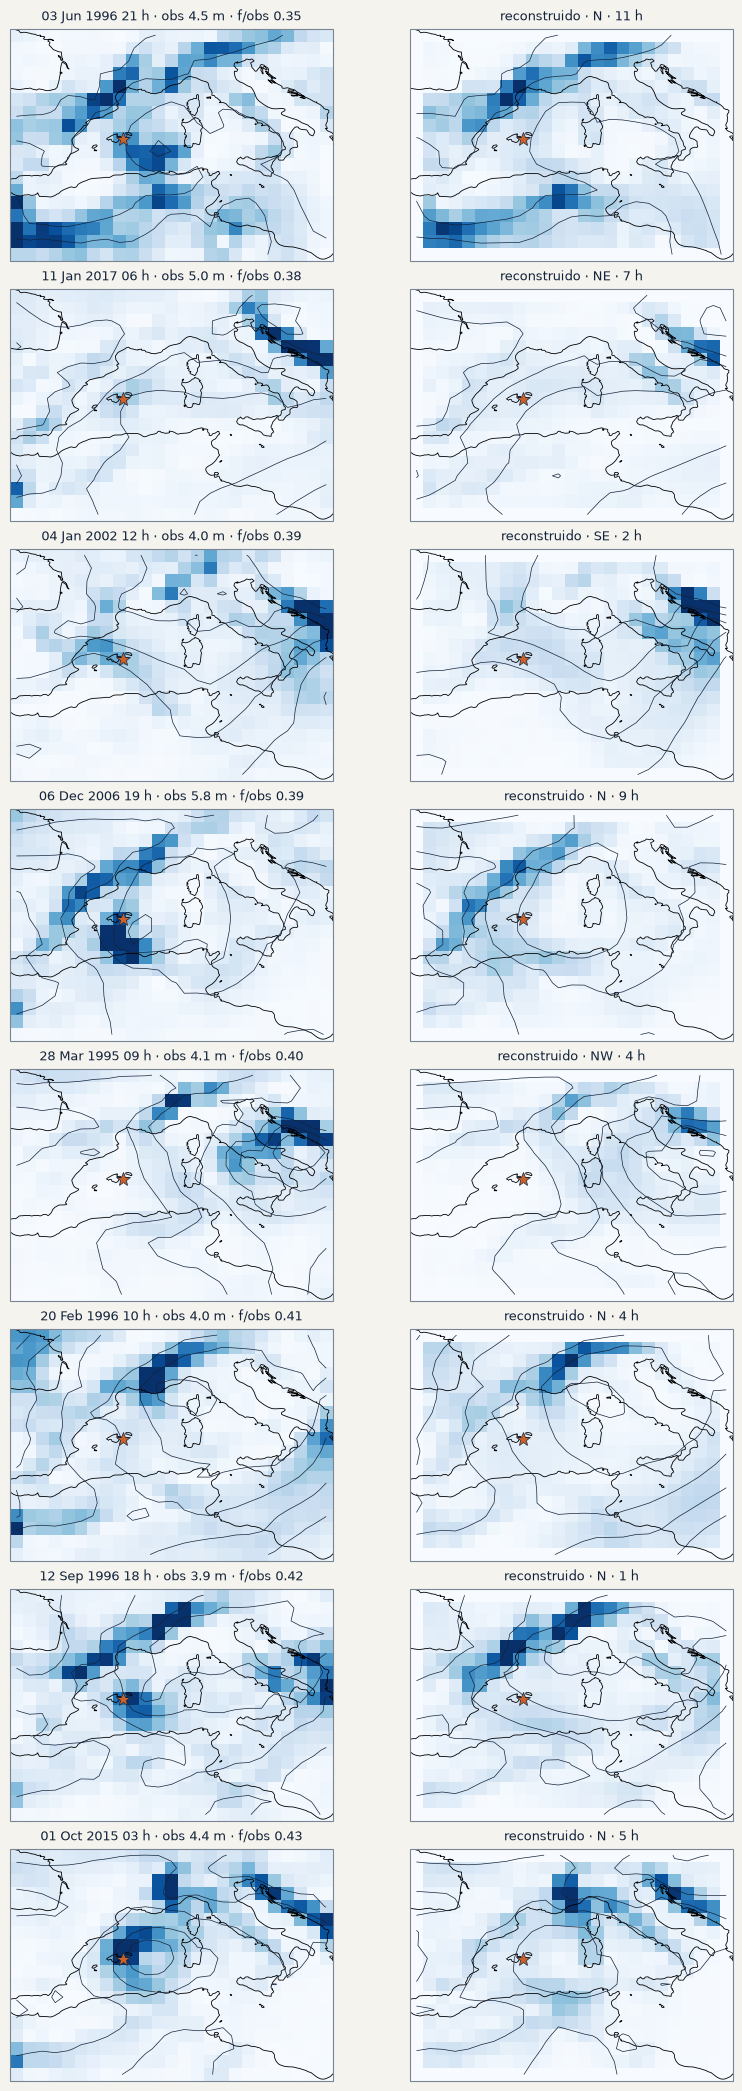

In [ ]:
peores = datos[datos.clase == "perdido"].sort_values("ratio").index[:8]
fig, axs = plt.subplots(len(peores), 2, figsize=(8.0, 2.6 * len(peores)), constrained_layout=True, subplot_kw=sub)
for f, t in enumerate(peores):
    k = int(np.flatnonzero(temporales.index == t)[0])
    pr, pc = msl_real.isel(time=k) / 100, msl_rec.isel(time=k) / 100
    gmax = float(np.nanpercentile(grad_real.isel(time=k).values, 99))
    mapa(axs[f, 0], grad_real.isel(time=k), f"{t:%d %b %Y %H h} · obs {datos.loc[t, 'hs_obs']:.1f} m · f/obs {datos.loc[t, 'ratio']:.2f}",
         cmap="Blues", contornos=pr)
    mapa(axs[f, 1], grad_rec.isel(time=k), f"reconstruido · {datos.loc[t, 'sector']} · {datos.loc[t, 'duración > U99 [h]']:.0f} h",
         cmap="Blues", contornos=pc)
    for ax in axs[f]:
        ax.collections[0].set_clim(0, gmax)
fig.savefig("figuras/temporales_perdidos_mapas.png", dpi=150)
plt.show()